# 🐧 Esercitazione 2 — Regressione lineare e alberi di regressione

**new ALF – Tutorato** · Corso di Laurea in Informatica · AA 2026/27

Nell'Esercitazione 1 abbiamo scritto un classificatore a mano, lo abbiamo valutato e abbiamo addestrato i primi alberi di decisione con scikit-learn. Oggi facciamo un passo avanti: vediamo **che tipo di problemi** si possono risolvere, la **regressione lineare** e gli **alberi di regressione**.

Useremo il dataset **Palmer Penguins**: le misure di 344 pinguini di tre specie (Adelie, Chinstrap e Gentoo), raccolte tra il 2007 e il 2009 su tre isole dell'arcipelago Palmer, in Antartide.


> ### ⚠️ Prima di tutto: fai la tua copia
> Questo notebook è condiviso in **sola lettura**: puoi eseguirlo e modificarlo, ma le modifiche **non verranno salvate**.
> Vai su **File → Salva una copia in Drive**. Si aprirà una nuova scheda con la *tua* copia (la trovi poi su Google Drive, nella cartella *Colab Notebooks*): lavora lì.

### Come si usa questo notebook
- Ogni **cella** si esegue con **Shift + Invio** (o con il tasto ▶ a sinistra). Esegui le celle **in ordine**, dall'alto verso il basso.
- Le celle segnate con **✏️** sono esercizi: modifica il codice dove indicato. Sotto ogni esercizio c'è un blocco **💡 Soluzione** chiuso: prova prima da solo. Se non ci riesci, **copia la soluzione nella cella** prima di andare avanti, perché le celle successive la usano.
- I box **🐍** spiegano le cose nuove di Python che incontriamo strada facendo.
- Le sezioni segnate con **⏩** sono approfondimenti.
- I box **📋** dicono quale problema stiamo risolvendo. I dati sono sempre gli stessi pinguini: cambia la **domanda**, e con lei il target `y`, le feature `X` e il modo di valutare il modello.
- Se qualcosa si rompe: menu **Runtime → Riavvia sessione ed esegui tutto** (*Restart session and run all*).

In [1]:
#@title ⚙️ Setup: esegui questa cella per prima (crea il file con i dati)
# Questa cella scrive nel workspace di Colab il file "pinguini.csv". Puoi vederlo nel pannello 📁 a sinistra.
# Nota: il workspace di Colab si svuota quando la sessione termina,
# quindi questa cella va rieseguita ogni volta che riapri il notebook.
#
# Dati: Palmer Penguins (Gorman, Williams & Fraser, 2014), raccolti alla Palmer Station (Antartide)
# e distribuiti con licenza CC0 dal pacchetto palmerpenguins di A. Horst, A. Hill e K. Gorman.
# Nomi delle colonne e valori del sesso tradotti in italiano.

PINGUINI_CSV = """specie,isola,becco_lunghezza,becco_profondita,pinna,peso,sesso
Adelie,Torgersen,39.1,18.7,181,3750,maschio
Adelie,Torgersen,39.5,17.4,186,3800,femmina
Adelie,Torgersen,40.3,18,195,3250,femmina
Adelie,Torgersen,,,,,
Adelie,Torgersen,36.7,19.3,193,3450,femmina
Adelie,Torgersen,39.3,20.6,190,3650,maschio
Adelie,Torgersen,38.9,17.8,181,3625,femmina
Adelie,Torgersen,39.2,19.6,195,4675,maschio
Adelie,Torgersen,34.1,18.1,193,3475,
Adelie,Torgersen,42,20.2,190,4250,
Adelie,Torgersen,37.8,17.1,186,3300,
Adelie,Torgersen,37.8,17.3,180,3700,
Adelie,Torgersen,41.1,17.6,182,3200,femmina
Adelie,Torgersen,38.6,21.2,191,3800,maschio
Adelie,Torgersen,34.6,21.1,198,4400,maschio
Adelie,Torgersen,36.6,17.8,185,3700,femmina
Adelie,Torgersen,38.7,19,195,3450,femmina
Adelie,Torgersen,42.5,20.7,197,4500,maschio
Adelie,Torgersen,34.4,18.4,184,3325,femmina
Adelie,Torgersen,46,21.5,194,4200,maschio
Adelie,Biscoe,37.8,18.3,174,3400,femmina
Adelie,Biscoe,37.7,18.7,180,3600,maschio
Adelie,Biscoe,35.9,19.2,189,3800,femmina
Adelie,Biscoe,38.2,18.1,185,3950,maschio
Adelie,Biscoe,38.8,17.2,180,3800,maschio
Adelie,Biscoe,35.3,18.9,187,3800,femmina
Adelie,Biscoe,40.6,18.6,183,3550,maschio
Adelie,Biscoe,40.5,17.9,187,3200,femmina
Adelie,Biscoe,37.9,18.6,172,3150,femmina
Adelie,Biscoe,40.5,18.9,180,3950,maschio
Adelie,Dream,39.5,16.7,178,3250,femmina
Adelie,Dream,37.2,18.1,178,3900,maschio
Adelie,Dream,39.5,17.8,188,3300,femmina
Adelie,Dream,40.9,18.9,184,3900,maschio
Adelie,Dream,36.4,17,195,3325,femmina
Adelie,Dream,39.2,21.1,196,4150,maschio
Adelie,Dream,38.8,20,190,3950,maschio
Adelie,Dream,42.2,18.5,180,3550,femmina
Adelie,Dream,37.6,19.3,181,3300,femmina
Adelie,Dream,39.8,19.1,184,4650,maschio
Adelie,Dream,36.5,18,182,3150,femmina
Adelie,Dream,40.8,18.4,195,3900,maschio
Adelie,Dream,36,18.5,186,3100,femmina
Adelie,Dream,44.1,19.7,196,4400,maschio
Adelie,Dream,37,16.9,185,3000,femmina
Adelie,Dream,39.6,18.8,190,4600,maschio
Adelie,Dream,41.1,19,182,3425,maschio
Adelie,Dream,37.5,18.9,179,2975,
Adelie,Dream,36,17.9,190,3450,femmina
Adelie,Dream,42.3,21.2,191,4150,maschio
Adelie,Biscoe,39.6,17.7,186,3500,femmina
Adelie,Biscoe,40.1,18.9,188,4300,maschio
Adelie,Biscoe,35,17.9,190,3450,femmina
Adelie,Biscoe,42,19.5,200,4050,maschio
Adelie,Biscoe,34.5,18.1,187,2900,femmina
Adelie,Biscoe,41.4,18.6,191,3700,maschio
Adelie,Biscoe,39,17.5,186,3550,femmina
Adelie,Biscoe,40.6,18.8,193,3800,maschio
Adelie,Biscoe,36.5,16.6,181,2850,femmina
Adelie,Biscoe,37.6,19.1,194,3750,maschio
Adelie,Biscoe,35.7,16.9,185,3150,femmina
Adelie,Biscoe,41.3,21.1,195,4400,maschio
Adelie,Biscoe,37.6,17,185,3600,femmina
Adelie,Biscoe,41.1,18.2,192,4050,maschio
Adelie,Biscoe,36.4,17.1,184,2850,femmina
Adelie,Biscoe,41.6,18,192,3950,maschio
Adelie,Biscoe,35.5,16.2,195,3350,femmina
Adelie,Biscoe,41.1,19.1,188,4100,maschio
Adelie,Torgersen,35.9,16.6,190,3050,femmina
Adelie,Torgersen,41.8,19.4,198,4450,maschio
Adelie,Torgersen,33.5,19,190,3600,femmina
Adelie,Torgersen,39.7,18.4,190,3900,maschio
Adelie,Torgersen,39.6,17.2,196,3550,femmina
Adelie,Torgersen,45.8,18.9,197,4150,maschio
Adelie,Torgersen,35.5,17.5,190,3700,femmina
Adelie,Torgersen,42.8,18.5,195,4250,maschio
Adelie,Torgersen,40.9,16.8,191,3700,femmina
Adelie,Torgersen,37.2,19.4,184,3900,maschio
Adelie,Torgersen,36.2,16.1,187,3550,femmina
Adelie,Torgersen,42.1,19.1,195,4000,maschio
Adelie,Torgersen,34.6,17.2,189,3200,femmina
Adelie,Torgersen,42.9,17.6,196,4700,maschio
Adelie,Torgersen,36.7,18.8,187,3800,femmina
Adelie,Torgersen,35.1,19.4,193,4200,maschio
Adelie,Dream,37.3,17.8,191,3350,femmina
Adelie,Dream,41.3,20.3,194,3550,maschio
Adelie,Dream,36.3,19.5,190,3800,maschio
Adelie,Dream,36.9,18.6,189,3500,femmina
Adelie,Dream,38.3,19.2,189,3950,maschio
Adelie,Dream,38.9,18.8,190,3600,femmina
Adelie,Dream,35.7,18,202,3550,femmina
Adelie,Dream,41.1,18.1,205,4300,maschio
Adelie,Dream,34,17.1,185,3400,femmina
Adelie,Dream,39.6,18.1,186,4450,maschio
Adelie,Dream,36.2,17.3,187,3300,femmina
Adelie,Dream,40.8,18.9,208,4300,maschio
Adelie,Dream,38.1,18.6,190,3700,femmina
Adelie,Dream,40.3,18.5,196,4350,maschio
Adelie,Dream,33.1,16.1,178,2900,femmina
Adelie,Dream,43.2,18.5,192,4100,maschio
Adelie,Biscoe,35,17.9,192,3725,femmina
Adelie,Biscoe,41,20,203,4725,maschio
Adelie,Biscoe,37.7,16,183,3075,femmina
Adelie,Biscoe,37.8,20,190,4250,maschio
Adelie,Biscoe,37.9,18.6,193,2925,femmina
Adelie,Biscoe,39.7,18.9,184,3550,maschio
Adelie,Biscoe,38.6,17.2,199,3750,femmina
Adelie,Biscoe,38.2,20,190,3900,maschio
Adelie,Biscoe,38.1,17,181,3175,femmina
Adelie,Biscoe,43.2,19,197,4775,maschio
Adelie,Biscoe,38.1,16.5,198,3825,femmina
Adelie,Biscoe,45.6,20.3,191,4600,maschio
Adelie,Biscoe,39.7,17.7,193,3200,femmina
Adelie,Biscoe,42.2,19.5,197,4275,maschio
Adelie,Biscoe,39.6,20.7,191,3900,femmina
Adelie,Biscoe,42.7,18.3,196,4075,maschio
Adelie,Torgersen,38.6,17,188,2900,femmina
Adelie,Torgersen,37.3,20.5,199,3775,maschio
Adelie,Torgersen,35.7,17,189,3350,femmina
Adelie,Torgersen,41.1,18.6,189,3325,maschio
Adelie,Torgersen,36.2,17.2,187,3150,femmina
Adelie,Torgersen,37.7,19.8,198,3500,maschio
Adelie,Torgersen,40.2,17,176,3450,femmina
Adelie,Torgersen,41.4,18.5,202,3875,maschio
Adelie,Torgersen,35.2,15.9,186,3050,femmina
Adelie,Torgersen,40.6,19,199,4000,maschio
Adelie,Torgersen,38.8,17.6,191,3275,femmina
Adelie,Torgersen,41.5,18.3,195,4300,maschio
Adelie,Torgersen,39,17.1,191,3050,femmina
Adelie,Torgersen,44.1,18,210,4000,maschio
Adelie,Torgersen,38.5,17.9,190,3325,femmina
Adelie,Torgersen,43.1,19.2,197,3500,maschio
Adelie,Dream,36.8,18.5,193,3500,femmina
Adelie,Dream,37.5,18.5,199,4475,maschio
Adelie,Dream,38.1,17.6,187,3425,femmina
Adelie,Dream,41.1,17.5,190,3900,maschio
Adelie,Dream,35.6,17.5,191,3175,femmina
Adelie,Dream,40.2,20.1,200,3975,maschio
Adelie,Dream,37,16.5,185,3400,femmina
Adelie,Dream,39.7,17.9,193,4250,maschio
Adelie,Dream,40.2,17.1,193,3400,femmina
Adelie,Dream,40.6,17.2,187,3475,maschio
Adelie,Dream,32.1,15.5,188,3050,femmina
Adelie,Dream,40.7,17,190,3725,maschio
Adelie,Dream,37.3,16.8,192,3000,femmina
Adelie,Dream,39,18.7,185,3650,maschio
Adelie,Dream,39.2,18.6,190,4250,maschio
Adelie,Dream,36.6,18.4,184,3475,femmina
Adelie,Dream,36,17.8,195,3450,femmina
Adelie,Dream,37.8,18.1,193,3750,maschio
Adelie,Dream,36,17.1,187,3700,femmina
Adelie,Dream,41.5,18.5,201,4000,maschio
Chinstrap,Dream,46.5,17.9,192,3500,femmina
Chinstrap,Dream,50,19.5,196,3900,maschio
Chinstrap,Dream,51.3,19.2,193,3650,maschio
Chinstrap,Dream,45.4,18.7,188,3525,femmina
Chinstrap,Dream,52.7,19.8,197,3725,maschio
Chinstrap,Dream,45.2,17.8,198,3950,femmina
Chinstrap,Dream,46.1,18.2,178,3250,femmina
Chinstrap,Dream,51.3,18.2,197,3750,maschio
Chinstrap,Dream,46,18.9,195,4150,femmina
Chinstrap,Dream,51.3,19.9,198,3700,maschio
Chinstrap,Dream,46.6,17.8,193,3800,femmina
Chinstrap,Dream,51.7,20.3,194,3775,maschio
Chinstrap,Dream,47,17.3,185,3700,femmina
Chinstrap,Dream,52,18.1,201,4050,maschio
Chinstrap,Dream,45.9,17.1,190,3575,femmina
Chinstrap,Dream,50.5,19.6,201,4050,maschio
Chinstrap,Dream,50.3,20,197,3300,maschio
Chinstrap,Dream,58,17.8,181,3700,femmina
Chinstrap,Dream,46.4,18.6,190,3450,femmina
Chinstrap,Dream,49.2,18.2,195,4400,maschio
Chinstrap,Dream,42.4,17.3,181,3600,femmina
Chinstrap,Dream,48.5,17.5,191,3400,maschio
Chinstrap,Dream,43.2,16.6,187,2900,femmina
Chinstrap,Dream,50.6,19.4,193,3800,maschio
Chinstrap,Dream,46.7,17.9,195,3300,femmina
Chinstrap,Dream,52,19,197,4150,maschio
Chinstrap,Dream,50.5,18.4,200,3400,femmina
Chinstrap,Dream,49.5,19,200,3800,maschio
Chinstrap,Dream,46.4,17.8,191,3700,femmina
Chinstrap,Dream,52.8,20,205,4550,maschio
Chinstrap,Dream,40.9,16.6,187,3200,femmina
Chinstrap,Dream,54.2,20.8,201,4300,maschio
Chinstrap,Dream,42.5,16.7,187,3350,femmina
Chinstrap,Dream,51,18.8,203,4100,maschio
Chinstrap,Dream,49.7,18.6,195,3600,maschio
Chinstrap,Dream,47.5,16.8,199,3900,femmina
Chinstrap,Dream,47.6,18.3,195,3850,femmina
Chinstrap,Dream,52,20.7,210,4800,maschio
Chinstrap,Dream,46.9,16.6,192,2700,femmina
Chinstrap,Dream,53.5,19.9,205,4500,maschio
Chinstrap,Dream,49,19.5,210,3950,maschio
Chinstrap,Dream,46.2,17.5,187,3650,femmina
Chinstrap,Dream,50.9,19.1,196,3550,maschio
Chinstrap,Dream,45.5,17,196,3500,femmina
Chinstrap,Dream,50.9,17.9,196,3675,femmina
Chinstrap,Dream,50.8,18.5,201,4450,maschio
Chinstrap,Dream,50.1,17.9,190,3400,femmina
Chinstrap,Dream,49,19.6,212,4300,maschio
Chinstrap,Dream,51.5,18.7,187,3250,maschio
Chinstrap,Dream,49.8,17.3,198,3675,femmina
Chinstrap,Dream,48.1,16.4,199,3325,femmina
Chinstrap,Dream,51.4,19,201,3950,maschio
Chinstrap,Dream,45.7,17.3,193,3600,femmina
Chinstrap,Dream,50.7,19.7,203,4050,maschio
Chinstrap,Dream,42.5,17.3,187,3350,femmina
Chinstrap,Dream,52.2,18.8,197,3450,maschio
Chinstrap,Dream,45.2,16.6,191,3250,femmina
Chinstrap,Dream,49.3,19.9,203,4050,maschio
Chinstrap,Dream,50.2,18.8,202,3800,maschio
Chinstrap,Dream,45.6,19.4,194,3525,femmina
Chinstrap,Dream,51.9,19.5,206,3950,maschio
Chinstrap,Dream,46.8,16.5,189,3650,femmina
Chinstrap,Dream,45.7,17,195,3650,femmina
Chinstrap,Dream,55.8,19.8,207,4000,maschio
Chinstrap,Dream,43.5,18.1,202,3400,femmina
Chinstrap,Dream,49.6,18.2,193,3775,maschio
Chinstrap,Dream,50.8,19,210,4100,maschio
Chinstrap,Dream,50.2,18.7,198,3775,femmina
Gentoo,Biscoe,46.1,13.2,211,4500,femmina
Gentoo,Biscoe,50,16.3,230,5700,maschio
Gentoo,Biscoe,48.7,14.1,210,4450,femmina
Gentoo,Biscoe,50,15.2,218,5700,maschio
Gentoo,Biscoe,47.6,14.5,215,5400,maschio
Gentoo,Biscoe,46.5,13.5,210,4550,femmina
Gentoo,Biscoe,45.4,14.6,211,4800,femmina
Gentoo,Biscoe,46.7,15.3,219,5200,maschio
Gentoo,Biscoe,43.3,13.4,209,4400,femmina
Gentoo,Biscoe,46.8,15.4,215,5150,maschio
Gentoo,Biscoe,40.9,13.7,214,4650,femmina
Gentoo,Biscoe,49,16.1,216,5550,maschio
Gentoo,Biscoe,45.5,13.7,214,4650,femmina
Gentoo,Biscoe,48.4,14.6,213,5850,maschio
Gentoo,Biscoe,45.8,14.6,210,4200,femmina
Gentoo,Biscoe,49.3,15.7,217,5850,maschio
Gentoo,Biscoe,42,13.5,210,4150,femmina
Gentoo,Biscoe,49.2,15.2,221,6300,maschio
Gentoo,Biscoe,46.2,14.5,209,4800,femmina
Gentoo,Biscoe,48.7,15.1,222,5350,maschio
Gentoo,Biscoe,50.2,14.3,218,5700,maschio
Gentoo,Biscoe,45.1,14.5,215,5000,femmina
Gentoo,Biscoe,46.5,14.5,213,4400,femmina
Gentoo,Biscoe,46.3,15.8,215,5050,maschio
Gentoo,Biscoe,42.9,13.1,215,5000,femmina
Gentoo,Biscoe,46.1,15.1,215,5100,maschio
Gentoo,Biscoe,44.5,14.3,216,4100,
Gentoo,Biscoe,47.8,15,215,5650,maschio
Gentoo,Biscoe,48.2,14.3,210,4600,femmina
Gentoo,Biscoe,50,15.3,220,5550,maschio
Gentoo,Biscoe,47.3,15.3,222,5250,maschio
Gentoo,Biscoe,42.8,14.2,209,4700,femmina
Gentoo,Biscoe,45.1,14.5,207,5050,femmina
Gentoo,Biscoe,59.6,17,230,6050,maschio
Gentoo,Biscoe,49.1,14.8,220,5150,femmina
Gentoo,Biscoe,48.4,16.3,220,5400,maschio
Gentoo,Biscoe,42.6,13.7,213,4950,femmina
Gentoo,Biscoe,44.4,17.3,219,5250,maschio
Gentoo,Biscoe,44,13.6,208,4350,femmina
Gentoo,Biscoe,48.7,15.7,208,5350,maschio
Gentoo,Biscoe,42.7,13.7,208,3950,femmina
Gentoo,Biscoe,49.6,16,225,5700,maschio
Gentoo,Biscoe,45.3,13.7,210,4300,femmina
Gentoo,Biscoe,49.6,15,216,4750,maschio
Gentoo,Biscoe,50.5,15.9,222,5550,maschio
Gentoo,Biscoe,43.6,13.9,217,4900,femmina
Gentoo,Biscoe,45.5,13.9,210,4200,femmina
Gentoo,Biscoe,50.5,15.9,225,5400,maschio
Gentoo,Biscoe,44.9,13.3,213,5100,femmina
Gentoo,Biscoe,45.2,15.8,215,5300,maschio
Gentoo,Biscoe,46.6,14.2,210,4850,femmina
Gentoo,Biscoe,48.5,14.1,220,5300,maschio
Gentoo,Biscoe,45.1,14.4,210,4400,femmina
Gentoo,Biscoe,50.1,15,225,5000,maschio
Gentoo,Biscoe,46.5,14.4,217,4900,femmina
Gentoo,Biscoe,45,15.4,220,5050,maschio
Gentoo,Biscoe,43.8,13.9,208,4300,femmina
Gentoo,Biscoe,45.5,15,220,5000,maschio
Gentoo,Biscoe,43.2,14.5,208,4450,femmina
Gentoo,Biscoe,50.4,15.3,224,5550,maschio
Gentoo,Biscoe,45.3,13.8,208,4200,femmina
Gentoo,Biscoe,46.2,14.9,221,5300,maschio
Gentoo,Biscoe,45.7,13.9,214,4400,femmina
Gentoo,Biscoe,54.3,15.7,231,5650,maschio
Gentoo,Biscoe,45.8,14.2,219,4700,femmina
Gentoo,Biscoe,49.8,16.8,230,5700,maschio
Gentoo,Biscoe,46.2,14.4,214,4650,
Gentoo,Biscoe,49.5,16.2,229,5800,maschio
Gentoo,Biscoe,43.5,14.2,220,4700,femmina
Gentoo,Biscoe,50.7,15,223,5550,maschio
Gentoo,Biscoe,47.7,15,216,4750,femmina
Gentoo,Biscoe,46.4,15.6,221,5000,maschio
Gentoo,Biscoe,48.2,15.6,221,5100,maschio
Gentoo,Biscoe,46.5,14.8,217,5200,femmina
Gentoo,Biscoe,46.4,15,216,4700,femmina
Gentoo,Biscoe,48.6,16,230,5800,maschio
Gentoo,Biscoe,47.5,14.2,209,4600,femmina
Gentoo,Biscoe,51.1,16.3,220,6000,maschio
Gentoo,Biscoe,45.2,13.8,215,4750,femmina
Gentoo,Biscoe,45.2,16.4,223,5950,maschio
Gentoo,Biscoe,49.1,14.5,212,4625,femmina
Gentoo,Biscoe,52.5,15.6,221,5450,maschio
Gentoo,Biscoe,47.4,14.6,212,4725,femmina
Gentoo,Biscoe,50,15.9,224,5350,maschio
Gentoo,Biscoe,44.9,13.8,212,4750,femmina
Gentoo,Biscoe,50.8,17.3,228,5600,maschio
Gentoo,Biscoe,43.4,14.4,218,4600,femmina
Gentoo,Biscoe,51.3,14.2,218,5300,maschio
Gentoo,Biscoe,47.5,14,212,4875,femmina
Gentoo,Biscoe,52.1,17,230,5550,maschio
Gentoo,Biscoe,47.5,15,218,4950,femmina
Gentoo,Biscoe,52.2,17.1,228,5400,maschio
Gentoo,Biscoe,45.5,14.5,212,4750,femmina
Gentoo,Biscoe,49.5,16.1,224,5650,maschio
Gentoo,Biscoe,44.5,14.7,214,4850,femmina
Gentoo,Biscoe,50.8,15.7,226,5200,maschio
Gentoo,Biscoe,49.4,15.8,216,4925,maschio
Gentoo,Biscoe,46.9,14.6,222,4875,femmina
Gentoo,Biscoe,48.4,14.4,203,4625,femmina
Gentoo,Biscoe,51.1,16.5,225,5250,maschio
Gentoo,Biscoe,48.5,15,219,4850,femmina
Gentoo,Biscoe,55.9,17,228,5600,maschio
Gentoo,Biscoe,47.2,15.5,215,4975,femmina
Gentoo,Biscoe,49.1,15,228,5500,maschio
Gentoo,Biscoe,47.3,13.8,216,4725,
Gentoo,Biscoe,46.8,16.1,215,5500,maschio
Gentoo,Biscoe,41.7,14.7,210,4700,femmina
Gentoo,Biscoe,53.4,15.8,219,5500,maschio
Gentoo,Biscoe,43.3,14,208,4575,femmina
Gentoo,Biscoe,48.1,15.1,209,5500,maschio
Gentoo,Biscoe,50.5,15.2,216,5000,femmina
Gentoo,Biscoe,49.8,15.9,229,5950,maschio
Gentoo,Biscoe,43.5,15.2,213,4650,femmina
Gentoo,Biscoe,51.5,16.3,230,5500,maschio
Gentoo,Biscoe,46.2,14.1,217,4375,femmina
Gentoo,Biscoe,55.1,16,230,5850,maschio
Gentoo,Biscoe,44.5,15.7,217,4875,
Gentoo,Biscoe,48.8,16.2,222,6000,maschio
Gentoo,Biscoe,47.2,13.7,214,4925,femmina
Gentoo,Biscoe,,,,,
Gentoo,Biscoe,46.8,14.3,215,4850,femmina
Gentoo,Biscoe,50.4,15.7,222,5750,maschio
Gentoo,Biscoe,45.2,14.8,212,5200,femmina
Gentoo,Biscoe,49.9,16.1,213,5400,maschio
"""

with open("pinguini.csv", "w", encoding="utf-8") as f:
    f.write(PINGUINI_CSV)

print("✅ File pinguini.csv creato!")

✅ File pinguini.csv creato!


In [2]:
#@title 🛠️ Funzioni di supporto per i grafici (esegui la cella, non serve leggerla)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_rgb

# Un colore fisso per ogni classe, così lo stesso pinguino ha sempre lo stesso colore
COLORI = {"Adelie": "#FF8C00", "Chinstrap": "#A034F0", "Gentoo": "#159090",
          "femmina": "#D9534F", "maschio": "#2C7FB8"}

def predici(modello, X):
    """Predizioni per X: funziona sia con un modello sklearn (che ha .predict)
    sia con una funzione scritta da noi che riceve un DataFrame."""
    if hasattr(modello, "predict"):
        return np.asarray(modello.predict(X))
    return np.asarray(modello(X))

def _griglia(X, passi=300):
    c1, c2 = X.columns
    m1 = (X[c1].max() - X[c1].min()) * 0.05
    m2 = (X[c2].max() - X[c2].min()) * 0.05
    xx, yy = np.meshgrid(np.linspace(X[c1].min() - m1, X[c1].max() + m1, passi),
                         np.linspace(X[c2].min() - m2, X[c2].max() + m2, passi))
    return xx, yy, pd.DataFrame({c1: xx.ravel(), c2: yy.ravel()})

def mostra_punti(X, y, titolo="", ax=None):
    """Scatter plot di due feature, un colore per classe."""
    nuovo = ax is None
    if nuovo:
        fig, ax = plt.subplots(figsize=(7, 5))
    c1, c2 = X.columns
    for classe in sorted(pd.unique(np.asarray(y))):
        sel = np.asarray(y) == classe
        ax.scatter(X[c1][sel], X[c2][sel], c=COLORI.get(classe, "gray"), label=classe,
                   edgecolors="k", linewidths=0.5, s=35)
    ax.set_xlabel(c1); ax.set_ylabel(c2); ax.set_title(titolo)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    if nuovo:
        plt.show()

def disegna_frontiera(modello, X, y, titolo="", ax=None):
    """Colora il piano secondo la classe predetta dal modello (frontiera decisionale)."""
    nuovo = ax is None
    if nuovo:
        fig, ax = plt.subplots(figsize=(7, 5))
    xx, yy, griglia = _griglia(X)
    pred = predici(modello, griglia)
    classi = sorted(set(pd.unique(pred)) | set(pd.unique(np.asarray(y))))
    indice = {c: i for i, c in enumerate(classi)}
    z = np.array([indice[p] for p in pred]).reshape(xx.shape)
    cmap = ListedColormap([COLORI.get(c, "gray") for c in classi])
    ax.contourf(xx, yy, z, alpha=0.25, cmap=cmap, levels=np.arange(len(classi) + 1) - 0.5)
    mostra_punti(X, y, titolo, ax=ax)
    if nuovo:
        plt.show()

def disegna_confidenza(modello, X, y, titolo="", ax=None):
    """Come disegna_frontiera, ma il colore è tanto più intenso quanto più il modello è sicuro."""
    nuovo = ax is None
    if nuovo:
        fig, ax = plt.subplots(figsize=(7, 5))
    xx, yy, griglia = _griglia(X)
    proba = modello.predict_proba(griglia)
    k = proba.shape[1]
    sicurezza = (proba.max(axis=1) - 1 / k) / (1 - 1 / k)       # 0 = indeciso, 1 = sicurissimo
    colori = np.array([to_rgb(COLORI.get(c, "gray")) for c in modello.classes_])[proba.argmax(axis=1)]
    immagine = 1 - 0.7 * sicurezza[:, None] * (1 - colori)       # sfuma verso il bianco se poco sicuro
    ax.imshow(immagine.reshape(xx.shape + (3,)), origin="lower", aspect="auto",
              extent=(xx.min(), xx.max(), yy.min(), yy.max()))
    mostra_punti(X, y, titolo, ax=ax)
    if nuovo:
        plt.show()

print("✅ Funzioni pronte: mostra_punti, disegna_frontiera, disegna_confidenza")

✅ Funzioni pronte: mostra_punti, disegna_frontiera, disegna_confidenza


### 🔁 Dall'Esercitazione 1 ci portiamo dietro
- **`X`** (maiuscola) sono le **feature**, l'input del modello; **`y`** è il **target**, l'output da predire.
- I dati si dividono in **training set** (per addestrare) e **test set** (per valutare alla fine), con `train_test_split`.
- Ogni modello di scikit-learn si usa allo stesso modo: lo **creo** scegliendo gli iperparametri, lo **addestro** con `.fit(X, y)`, lo **uso** con `.predict(X)`.
- Un modello che va benissimo sul training e male sul test è in **overfitting**.

---
# Parte 1 — I dati e i tipi di problema

Per ogni pinguino il dataset riporta la specie, l'isola, due misure del becco, la lunghezza della pinna, il peso e, quando è stato registrato, il sesso.

### 1.1 Carichiamo e puliamo i dati

In [3]:
pinguini = pd.read_csv("pinguini.csv")
pinguini.head()

,specie,isola,becco_lunghezza,becco_profondita,pinna,peso,sesso
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,maschio
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,femmina
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,femmina
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,femmina


| Colonna | Significato |
|---|---|
| `specie` | Adelie, Chinstrap o Gentoo |
| `isola` | Biscoe, Dream o Torgersen |
| `becco_lunghezza`, `becco_profondita` | lunghezza e "altezza" del becco, in mm |
| `pinna` | lunghezza della pinna, in mm |
| `peso` | in grammi |
| `sesso` | maschio o femmina |

Nella quarta riga ci sono dei `NaN` (*Not a Number*): è il modo in cui pandas indica un **valore mancante**. Contiamoli.

In [4]:
# .isna() restituisce una tabella di True/False (True = valore mancante);
# .sum() conta i True colonna per colonna (True vale 1, False vale 0)
pinguini.isna().sum()

specie               0
isola                0
becco_lunghezza      2
becco_profondita     2
pinna                2
peso                 2
sesso               11
dtype: int64

I buchi sono di due tipi:
- **2 pinguini** non hanno **nessuna** misura;
- **9 pinguini** hanno tutte le misure ma **non il sesso**.

In questa esercitazione non li usiamo: con `.dropna()` eliminiamo tutte le righe che hanno almeno un valore mancante.

In [ ]:
df = pinguini.dropna()          # .dropna() elimina tutte le righe con almeno un valore mancante

print("Pinguini prima della pulizia:", len(pinguini))
print("Pinguini dopo la pulizia:    ", len(df))
df["specie"].value_counts()

Prima di costruire qualsiasi modello, **guardiamo i dati**. Il *pairplot* della libreria **seaborn** disegna uno scatter plot per ogni coppia di misure.

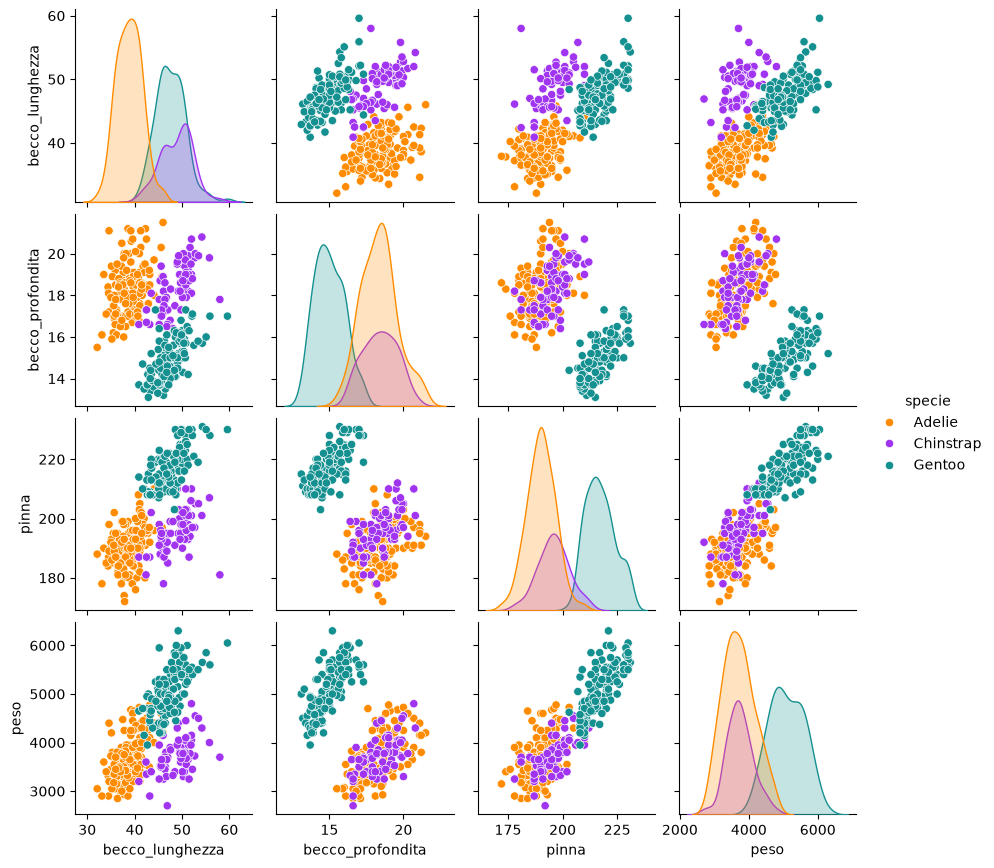

In [6]:
import seaborn as sns    # libreria di grafici statistici costruita sopra matplotlib

sns.pairplot(df, hue="specie", palette=COLORI, height=2.2,
             vars=["becco_lunghezza", "becco_profondita", "pinna", "peso"])
plt.show()

> 🤔 Quale **coppia** di misure separa meglio le tre specie? E quale misura da sola basta a riconoscere i Gentoo?

### 1.2 Una tabella, tre problemi
La stessa tabella può rispondere a domande diverse. **Cambia il target `y`**, e con lui il tipo di problema:

| Domanda | Target `y` | Tipo di problema |
|---|---|---|
| *"Quanto pesa?"* | `peso`: un numero | **regressione** |
| *"È maschio o femmina?"* | `sesso`: 2 valori possibili | **classificazione binaria** |
| *"Che specie è?"* | `specie`: 3 valori possibili | **classificazione multiclasse** |

In [7]:
target_possibili = {
    "peso": df["peso"],
    "sesso": df["sesso"],
    "specie": df["specie"],
}
# .items() scorre le coppie (chiave, valore) del dizionario
for nome, y in target_possibili.items():
    # .dtype = tipo dei valori; .nunique() = quanti valori diversi ci sono
    print(f"{nome:<7} tipo: {str(y.dtype):<8} valori diversi: {y.nunique()}")

peso    tipo: float64  valori diversi: 93
sesso   tipo: str      valori diversi: 2
specie  tipo: str      valori diversi: 3


Vediamo i tre problemi sullo **stesso grafico**: cambia solo il colore dei punti, cioè cosa vogliamo predire.

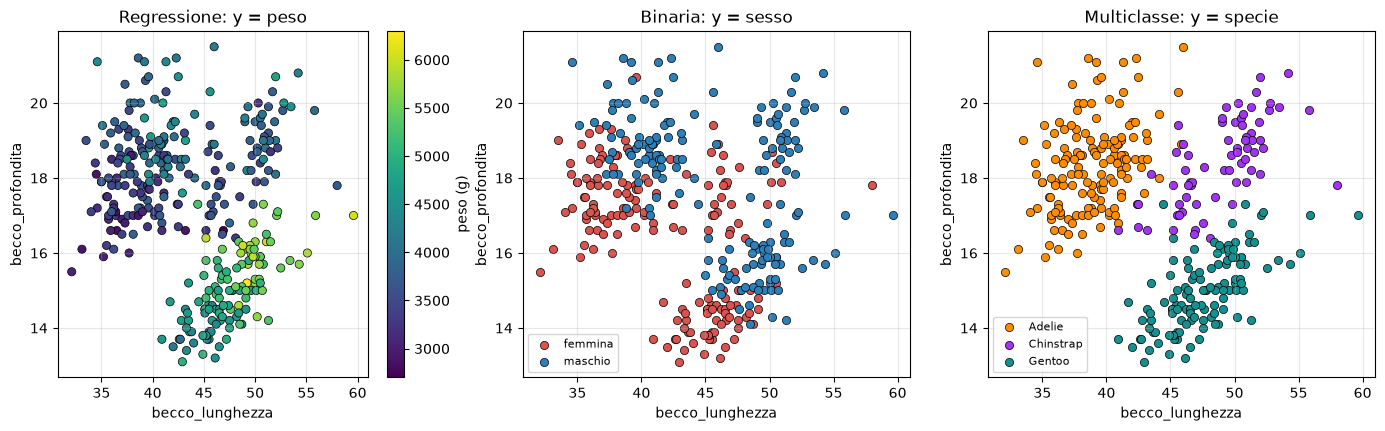

In [8]:
X_becco = df[["becco_lunghezza", "becco_profondita"]]

# plt.subplots(1, 3) crea una figura con 1 riga e 3 colonne di grafici: "assi" è un array di 3 elementi
fig, assi = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) regressione: il colore è un numero continuo (il peso)
punti = assi[0].scatter(X_becco["becco_lunghezza"], X_becco["becco_profondita"], c=df["peso"],
                        cmap="viridis", edgecolors="k", linewidths=0.5, s=35)
fig.colorbar(punti, ax=assi[0], label="peso (g)")
assi[0].set_xlabel("becco_lunghezza"); assi[0].set_ylabel("becco_profondita")
assi[0].set_title("Regressione: y = peso"); assi[0].grid(alpha=0.3)

# 2) classificazione binaria e 3) multiclasse: il colore è un'etichetta
mostra_punti(X_becco, df["sesso"], "Binaria: y = sesso", ax=assi[1])
mostra_punti(X_becco, df["specie"], "Multiclasse: y = specie", ax=assi[2])
plt.show()

---
# Parte 2 — Regressione lineare: stimare il peso dalla pinna

> 📋 **Il problema: quanto pesa un pinguino?**
> - **Dati:** tutti i pinguini della Parte 1
> - **Target `y`:** `peso`, un **numero** (in grammi)
> - **Feature `X`:** `pinna` (nella 2.6 aggiungeremo altre misure)
> - **Tipo di problema:** **regressione**
> - **Come lo valutiamo:** MSE

### 2.1 Guardiamo i dati

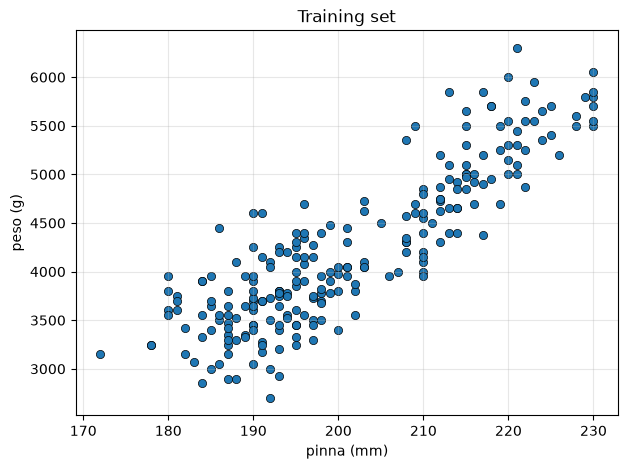

In [9]:
from sklearn.model_selection import train_test_split

X_peso = df[["pinna"]]      # doppie parentesi: un DataFrame con una sola colonna (sklearn vuole X "a tabella" )
y_peso = df["peso"]         # parentesi singole: una colonna

X_peso_train, X_peso_test, y_peso_train, y_peso_test = train_test_split(
    X_peso, y_peso, test_size=0.3, random_state=0)

plt.figure(figsize=(7, 5))
plt.scatter(X_peso_train["pinna"], y_peso_train, edgecolors="k", linewidths=0.5, s=35)
plt.xlabel("pinna (mm)"); plt.ylabel("peso (g)"); plt.title("Training set")
plt.grid(alpha=0.3)
plt.show()

I punti stanno più o meno lungo una **retta**. Un modello lineare con una feature è proprio una retta:

$$\hat{y} = w \cdot x + b$$

dove $x$ è la pinna, $w$ la **pendenza** e $b$ l'**intercetta** (nelle slide: $w_0 + w_a x_a$). Addestrare il modello vuol dire **trovare i valori di $w$ e $b$**.

### 2.2 Quanto è buona una retta? L'MSE
Per confrontare due rette serve un numero. Nella regressione non si contano TP e FP: si misura **quanto sono lontane** le predizioni dai valori veri. L'**errore quadratico medio** (*Mean Squared Error*) è:

$$MSE = \frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2$$

Le differenze $y_i - \hat y_i$ si chiamano **residui**. Elevarle al quadrato evita che errori positivi e negativi si compensino, e pesa di più gli errori grandi.

Non serve scriverla a mano: scikit-learn ha l'MSE già pronto, nella funzione `mean_squared_error`. Proviamola sui due array di prima.

In [10]:
from sklearn.metrics import mean_squared_error    # l'MSE già pronto in scikit-learn

y = [3, 5, 7]
y_pred = [2, 5, 9]

print(f"{mean_squared_error(y, y_pred):.2f}")           # (1 + 0 + 4) / 3 = 1.67

1.67


### 2.3 ✏️ Esercizio: sei tu la regressione
La retta è

$$\hat{y} = w \cdot x + b$$

- $x$ è la lunghezza della pinna (in mm) e $\hat y$ il peso stimato (in g);
- $w$ è la **pendenza**: di quanti grammi cresce il peso per ogni millimetro di pinna in più;
- $b$ è l'**intercetta**: il valore di $\hat y$ quando $x = 0$.

Usa i due slider per cambiare $w$ e $b$. Nel titolo vedi la retta e il suo MSE sul training set; le linee grigie sono i **residui**. **Trova la retta con l'MSE più basso possibile** e scrivi i valori di $w$ e $b$ nella cella successiva.

💡 *Attenzione*: cambiando $w$ la retta ruota attorno al punto con $x = 0$, che è molto a sinistra del grafico (i dati vanno da circa 170 a 230 mm). Per questo, quando aumenti $w$, la retta nel grafico **si alza** oltre a diventare più ripida. Dopo ogni modifica di $w$, riporta la retta sui dati con $b$.

In [11]:
from ipywidgets import FloatSlider, Image, VBox, Layout   # ipywidgets: elementi interattivi nei notebook
from IPython.display import display
import io                                            # per salvare il grafico in memoria invece che su file

fig, ax = plt.subplots(figsize=(6, 3.75))             # una sola figura, che ridisegniamo a ogni movimento
plt.close(fig)                                       # non mostrarla qui: la mostriamo dentro `immagine`

def prova_retta(w, b):
    """Disegna la retta ŷ = w·x + b sopra i dati di training, con i residui e l'MSE."""
    x = X_peso_train["pinna"]
    pred = w * x + b                                   # una predizione per ogni pinguino, senza for
    ax.clear()                                         # cancella il disegno precedente
    ax.vlines(x, pred, y_peso_train, color="gray", alpha=0.4, linewidth=1)   # i residui
    ax.scatter(x, y_peso_train, edgecolors="k", linewidths=0.5, s=35)
    xs = np.array([170, 235])
    ax.plot(xs, w * xs + b, color="crimson", linewidth=2)
    ax.set_ylim(2000, 7000)
    ax.set_xlabel("pinna (mm)"); ax.set_ylabel("peso (g)"); ax.grid(alpha=0.3)
    segno = "+" if b >= 0 else "−"
    ax.set_title(f"ŷ = {w:.2f} · x {segno} {abs(b):.2f}      MSE = {mean_squared_error(y_peso_train, pred):.2f}")
    return fig

# continuous_update=True: il grafico si aggiorna mentre trascini lo slider
slider_w = FloatSlider(min=0, max=80, step=0.5, value=20, description="w", continuous_update=True,
                       layout=Layout(width="600px"))   # slider più lungo: più facile da regolare
slider_b = FloatSlider(min=-10000, max=5000, step=50, value=0, description="b", continuous_update=True,
                       layout=Layout(width="600px"))
immagine = Image(format="png")                         # un'immagine che sostituiamo a ogni movimento

def aggiorna(cambiamento=None):
    memoria = io.BytesIO()                             # un "file" che sta in memoria
    prova_retta(slider_w.value, slider_b.value).savefig(memoria, format="png", bbox_inches="tight")
    immagine.value = memoria.getvalue()                # al posto della vecchia immagine mette la nuova

slider_w.observe(aggiorna, names="value")              # quando cambia uno slider, richiama aggiorna
slider_b.observe(aggiorna, names="value")
display(VBox([slider_w, slider_b, immagine]))
aggiorna()

*Se gli slider non compaiono, puoi chiamare la funzione a mano, per esempio `prova_retta(40, -4000)`.*

In [12]:
# ✏️ scrivi qui la tua retta migliore
mio_w = 64.5
mio_b = -9050

### 2.4 Ora lo fa l'algoritmo: `LinearRegression`

In [13]:
from sklearn.linear_model import LinearRegression

regressione = LinearRegression()             # 1) creo il modello
regressione.fit(X_peso_train, y_peso_train)  # 2) training: trova w e b

w_appreso = regressione.coef_[0]      # coef_ contiene un peso per ogni feature (qui una sola)
b_appreso = regressione.intercept_
print(f"Retta appresa: ŷ = {w_appreso:.2f} · pinna {b_appreso:+.2f}")

Retta appresa: ŷ = 51.23 · pinna -6089.73


Il modello è **interpretabile**: ogni millimetro di pinna in più vale circa `w_appreso` grammi di peso.

Confrontiamo la tua retta con quella appresa, sul training e sul test set.

In [14]:
righe = []
for nome, w, b in [("La mia retta", mio_w, mio_b), ("LinearRegression", w_appreso, b_appreso)]:
    mse_train = mean_squared_error(y_peso_train, w * X_peso_train["pinna"] + b)
    mse_test = mean_squared_error(y_peso_test, w * X_peso_test["pinna"] + b)
    righe.append({"modello": nome, "MSE train": mse_train, "MSE test": mse_test})

pd.DataFrame(righe).round(2)

,modello,MSE train,MSE test
0,La mia retta,267636.75,311944.69
1,LinearRegression,153246.82,155816.46


📌 **Perché l'MSE è un numero così grande?** L'MSE è la media dei residui **al quadrato**, quindi si misura nell'unità del target al quadrato: qui i **grammi al quadrato** (g²). Un residuo di 400 g diventa $400^2 = 160\,000$ g², e la media di tanti quadrati così finisce nelle centinaia di migliaia.

Se il peso fosse in chilogrammi, la stessa retta avrebbe un MSE un milione di volte più piccolo: 400 g sono 0,4 kg, e $0{,}4^2 = 0{,}16$. Il modello sarebbe identico, cambierebbe solo il numero.

Quindi il valore dell'MSE, da solo, non dice se un modello è buono o no: serve un **termine di paragone**. Il più semplice è un modello che ignora la pinna e prevede **sempre il peso medio** del training set.

In [15]:
media_train = y_peso_train.mean()                          # il peso medio dei pinguini di training
sempre_media = np.full(len(y_peso_test), media_train)      # np.full: un array lungo quanto il test set, tutto uguale alla media
print(f"Prevedo sempre {media_train:.2f} g → MSE test = {mean_squared_error(y_peso_test, sempre_media):.2f}")
print(f"LinearRegression          → MSE test = {mean_squared_error(y_peso_test, regressione.predict(X_peso_test)):.2f}")

Prevedo sempre 4232.30 g → MSE test = 670791.94
LinearRegression          → MSE test = 155816.46


Usando la pinna l'MSE scende di circa **4 volte** rispetto a chi tira a indovinare con la media: la retta è utile. È così che si legge l'MSE: **confrontando modelli diversi sugli stessi dati**, come faremo nella Parte 2.6 aggiungendo altre misure.

### 2.5 Come trova la retta? I minimi quadrati
`LinearRegression` sceglie i valori di $w$ e $b$ che rendono l'MSE **il più piccolo possibile**: per questo il metodo si chiama **minimi quadrati**. Il nome si capisce con un disegno: il quadrato di un residuo, $(y_i - \hat y_i)^2$, è l'**area di un quadrato** di lato $|y_i - \hat y_i|$, e l'MSE è la media di queste aree.

Per vederlo usiamo pochi punti di esempio, con la stessa unità di misura sui due assi. Sui pinguini non si potrebbe: un asse è in mm e l'altro in g, e i quadrati verrebbero rettangoli.

Nell'animazione la retta ruota attorno al **punto medio** dei dati, da cui passa sempre la retta migliore. A sinistra vedi i quadrati dei residui, a destra l'MSE in funzione della pendenza $w$. Esegui la cella e premi ▶.

In [16]:
#@title 🎬 Animazione: i minimi quadrati (esegui la cella e premi ▶)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle
from IPython.display import HTML

# pochi punti di esempio, con la stessa unità di misura sui due assi
x_es = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0])
y_es = np.array([2.0, 3.6, 2.8, 5.2, 4.4, 6.6, 6.0])

w_ottimo, b_ottimo = np.polyfit(x_es, y_es, 1)        # la retta dei minimi quadrati
x_medio, y_medio = x_es.mean(), y_es.mean()           # la retta migliore passa sempre per il punto medio

def mse_di(w):
    b = y_medio - w * x_medio                          # la retta ruota attorno al punto medio
    return np.mean((y_es - (w * x_es + b)) ** 2)

# la pendenza va da 0 a oltre l'ottimo, poi torna indietro e si ferma sull'ottimo
w_frames = np.concatenate([np.linspace(0, 1.6, 30), np.linspace(1.6, w_ottimo, 22),
                           np.full(10, w_ottimo)])
w_curva = np.linspace(-0.1, 1.7, 200)

fig, (ax_retta, ax_mse) = plt.subplots(1, 2, figsize=(10, 4.5), dpi=72)
ax_mse.plot(w_curva, [mse_di(w) for w in w_curva], color="gray")
ax_mse.axvline(w_ottimo, color="seagreen", linestyle="--", linewidth=1, label=f"minimo: w = {w_ottimo:.2f}")
punto_mse, = ax_mse.plot([], [], "o", color="crimson", markersize=9)
ax_mse.set_xlabel("pendenza w"); ax_mse.set_ylabel("MSE"); ax_mse.grid(alpha=0.3)
ax_mse.set_title("L'MSE al variare di w"); ax_mse.legend(loc="upper center")

def disegna(i):
    w = w_frames[i]
    b = y_medio - w * x_medio
    pred = w * x_es + b
    ax_retta.clear()
    for xi, yi, pi in zip(x_es, y_es, pred):
        r = yi - pi                                    # residuo
        ax_retta.add_patch(Rectangle((xi, min(yi, pi)), abs(r), abs(r),
                                     color="crimson", alpha=0.25))   # quadrato di lato |residuo|
        ax_retta.plot([xi, xi], [yi, pi], color="crimson", linewidth=1)
    ax_retta.scatter(x_es, y_es, color="steelblue", edgecolors="k", zorder=3, s=50)
    xs = np.array([0, 10])
    ax_retta.plot(xs, w * xs + b, color="k", linewidth=2)
    ax_retta.set_xlim(0, 10); ax_retta.set_ylim(-1, 9); ax_retta.set_aspect("equal")
    ax_retta.grid(alpha=0.3); ax_retta.set_xlabel("x"); ax_retta.set_ylabel("y")
    ax_retta.set_title(f"ŷ = {w:.2f}·x {'+' if b >= 0 else '−'} {abs(b):.2f}     MSE = {mse_di(w):.2f}")
    punto_mse.set_data([w], [mse_di(w)])

animazione = FuncAnimation(fig, disegna, frames=len(w_frames), interval=100)
plt.close(fig)                                         # mostriamo solo l'animazione, non la figura ferma
HTML(animazione.to_jshtml())

📌 L'MSE in funzione di $w$ è una curva con **un solo minimo**: la retta migliore è quella in cui la somma delle aree dei quadrati è più piccola. Per la regressione lineare esiste una formula che trova direttamente questo minimo, ed è quella che usa `LinearRegression`.

### 2.6 Più misure: dalla retta al piano
Con **due** feature il modello lineare diventa un **piano**:

$$\hat{y} = w_0 + w_{pinna} \cdot x_{pinna} + w_{becco} \cdot x_{becco}$$

Il grafico qui sotto è **interattivo**: trascinalo con il mouse per ruotarlo. Lo disegniamo con **plotly**, una libreria per grafici interattivi.

In [17]:
import plotly.graph_objects as go

X2 = df[["pinna", "becco_lunghezza"]]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y_peso, test_size=0.3, random_state=0)
regressione2 = LinearRegression().fit(X2_train, y2_train)
print(f"Pesi: pinna {regressione2.coef_[0]:.2f}, becco_lunghezza {regressione2.coef_[1]:.2f} | intercetta: {regressione2.intercept_:.2f}")

# il piano: calcolo la predizione su una griglia di valori (pinna, becco)
pp, bb = np.meshgrid(np.linspace(170, 235, 20), np.linspace(32, 60, 20))
griglia = pd.DataFrame({"pinna": pp.ravel(), "becco_lunghezza": bb.ravel()})
zz = regressione2.predict(griglia).reshape(pp.shape)

fig = go.Figure()
fig.add_trace(go.Scatter3d(x=X2_train["pinna"], y=X2_train["becco_lunghezza"], z=y2_train,
                           mode="markers", marker=dict(size=3, color="steelblue"), name="pinguini"))
fig.add_trace(go.Surface(x=pp, y=bb, z=zz, opacity=0.5, showscale=False,
                         colorscale=[[0, "crimson"], [1, "crimson"]], name="piano"))
fig.update_layout(height=550, margin=dict(l=0, r=0, t=30, b=0),
                  scene=dict(xaxis_title="pinna (mm)", yaxis_title="becco_lunghezza (mm)", zaxis_title="peso (g)"))
fig.show()

Pesi: pinna 50.28, becco_lunghezza 3.90 | intercetta: -6070.97


E se volessimo usare anche **specie**, **isola** e **sesso**? Sono parole, ma il modello lavora solo con numeri: le categorie vanno **codificate**. Il modo più comune è il **one-hot encoding**: una colonna 0/1 per ogni valore possibile.

> 🐍 `pd.get_dummies` crea le colonne 0/1. Con `drop_first=True` toglie la prima di ogni gruppo, perché è ridondante: se un pinguino non è né Chinstrap né Gentoo, è per forza Adelie.

In [18]:
X_tutte = pd.get_dummies(df.drop(columns=["peso"]),            # tutte le colonne tranne il target
                         columns=["specie", "isola", "sesso"], drop_first=True, dtype=int)
X_tutte.head()

,becco_lunghezza,becco_profondita,pinna,specie_Chinstrap,specie_Gentoo,isola_Dream,isola_Torgersen,sesso_maschio
0,39.1,18.7,181.0,0,0,0,1,1
1,39.5,17.4,186.0,0,0,0,1,0
2,40.3,18.0,195.0,0,0,0,1,0
4,36.7,19.3,193.0,0,0,0,1,0
5,39.3,20.6,190.0,0,0,0,1,1


In [19]:
insiemi_di_feature = {
    "solo pinna": ["pinna"],
    "pinna + becco_lunghezza": ["pinna", "becco_lunghezza"],
    "tutte (con le categorie)": list(X_tutte.columns),
}

righe = []
for nome, colonne in insiemi_di_feature.items():
    Xa, Xb, ya, yb = train_test_split(X_tutte[colonne], y_peso, test_size=0.3, random_state=0)  # stessa divisione di prima
    modello = LinearRegression().fit(Xa, ya)
    righe.append({"feature": nome, "MSE test": mean_squared_error(yb, modello.predict(Xb))})
pd.DataFrame(righe).round(2)

,feature,MSE test
0,solo pinna,155816.46
1,pinna + becco_lunghezza,155230.77
2,tutte (con le categorie),81692.13


> 🤔 Aggiungere il becco non serve quasi a niente, aggiungere specie e sesso invece migliora molto. Perché? Guarda i pesi del modello completo: quanto pesa in più, a parità di misure, un maschio? E un Gentoo?


In [20]:
modello_completo = LinearRegression().fit(X_tutte, y_peso)
pd.Series(modello_completo.coef_, index=X_tutte.columns).round(2)

becco_lunghezza      18.19
becco_profondita     67.58
pinna                16.24
specie_Chinstrap   -260.31
specie_Gentoo       987.76
isola_Dream         -13.10
isola_Torgersen     -48.06
sesso_maschio       387.22
dtype: float64

### 2.7 Un albero al posto della retta
Stesso problema, **nuovo modello**: stimiamo ancora il peso dalla pinna, con la stessa divisione train/test, ma al posto della retta usiamo un **albero**.

Un albero può fare anche **regressione**: ogni foglia predice la **media** dei pesi dei pinguini che ci arrivano, e l'impurità di un nodo è la sua **varianza**, cioè l'MSE rispetto alla media.

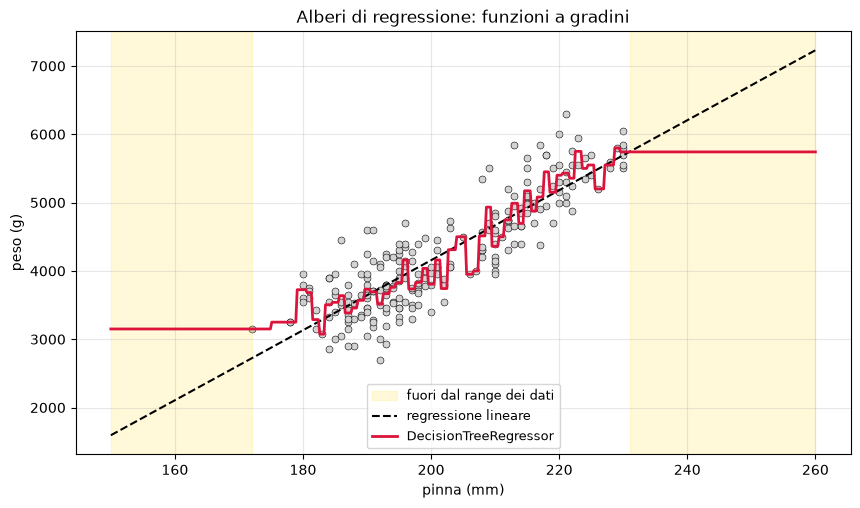

In [25]:
from sklearn.tree import DecisionTreeRegressor

pinne = pd.DataFrame({"pinna": np.linspace(150, 260, 500)})   # anche FUORI dal range dei dati (172-231 mm)

plt.figure(figsize=(10, 5.5))
plt.scatter(X_peso_train["pinna"], y_peso_train, color="lightgray", edgecolors="k", linewidths=0.4, s=25)
plt.axvspan(150, X_peso["pinna"].min(), color="gold", alpha=0.15)     # zone senza dati di training
plt.axvspan(X_peso["pinna"].max(), 260, color="gold", alpha=0.15, label="fuori dal range dei dati")
plt.plot(pinne["pinna"], regressione.predict(pinne), color="k", linestyle="--", label="regressione lineare")

albero_reg = DecisionTreeRegressor( random_state=0).fit(X_peso_train, y_peso_train)
mse_test = mean_squared_error(y_peso_test, albero_reg.predict(X_peso_test))
plt.plot(pinne["pinna"], albero_reg.predict(pinne), linewidth=2,
            label=f"DecisionTreeRegressor", color="crimson")

plt.xlabel("pinna (mm)"); plt.ylabel("peso (g)"); plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.title("Alberi di regressione: funzioni a gradini")
plt.show()

In [26]:
print("MSE test LinearRegression:", mean_squared_error(y_peso_test, regressione.predict(X_peso_test)))
print("MSE test DecisionTreeRegressor:", mean_squared_error(y_peso_test, albero_reg.predict(X_peso_test)))

MSE test LinearRegression: 155816.46211139104
MSE test DecisionTreeRegressor: 178079.01453083695


In [27]:
# Due pinguini con la pinna fuori dal range dei dati di training: 160 mm e 250 mm
nuovi = pd.DataFrame({"pinna": [160, 250]})
albero_reg = DecisionTreeRegressor(max_depth=4, random_state=0).fit(X_peso_train, y_peso_train)
pd.DataFrame({"pinna (mm)": nuovi["pinna"],
              "regressione lineare (g)": regressione.predict(nuovi).round(0),
              "albero max_depth=4 (g)": albero_reg.predict(nuovi).round(0)})

,pinna (mm),regressione lineare (g),albero max_depth=4 (g)
0,160,2107.0,3217.0
1,250,6717.0,5750.0


📌 L'albero predice una **funzione costante a tratti** (a gradini). Fuori dal range dei dati di training **non estrapola**: resta fermo sull'ultimo gradino. La retta invece continua a crescere. Chi ha ragione dipende dal problema, ma è un limite da conoscere, soprattutto con trend e serie temporali.

### 2.8 ⏩ Il contrario: la regressione per classificare
Nella 2.7 abbiamo usato un albero per fare **regressione**. Si può fare anche il contrario: usare la regressione lineare per **classificare**. Per vederlo cambiamo problema.

> 📋 **Il problema: che specie è?**
> - **Dati:** i pinguini Adelie e Chinstrap, le due specie più simili tra loro
> - **Target `y`:** `specie`, un'**etichetta**: Adelie o Chinstrap
> - **Feature `X`:** `becco_lunghezza` e `becco_profondita`
> - **Tipo di problema:** **classificazione binaria**
> - **Come lo valutiamo:** accuracy

> 🤔 **Le feature utili dipendono dalla domanda.** Nella 2.6, aggiungere `becco_lunghezza` alla pinna non migliorava quasi per niente la stima del peso. Vuol dire che il becco è una misura poco utile? Guarda le misure medie delle due specie qui sotto: quale misura serve per distinguere un Adelie da un Chinstrap? E la pinna, la migliore per il peso, serve anche qui?

> 🐍 `.groupby("specie")` divide la tabella in gruppi, uno per specie; `.mean()` calcola la media di ogni colonna dentro ciascun gruppo.

In [28]:
due_specie = df[df["specie"].isin(["Adelie", "Chinstrap"])]     # .isin: tiene solo le righe con quei valori
misure = ["becco_lunghezza", "becco_profondita", "pinna", "peso"]
due_specie.groupby("specie")[misure].mean().round(2)              # la media di ogni misura, specie per specie

,becco_lunghezza,becco_profondita,pinna,peso
specie,,,,
Adelie,38.82,18.35,190.10,3706.16
Chinstrap,48.83,18.42,195.82,3733.09


<details>
<summary><b>💡 Risposta</b> (clicca per aprire, ma prima prova a rispondere!)</summary>

Per distinguere le due specie la misura decisiva è **`becco_lunghezza`**: in media il becco dei Chinstrap è circa 1 cm più lungo di quello degli Adelie. Profondità del becco, pinna e peso invece sono quasi uguali nelle due specie, quindi da sole servono a poco. La pinna, la feature migliore per stimare il peso, qui è tra le meno utili.

Questo non contraddice la 2.6. Il becco non è inutile per il peso: è **ridondante** rispetto alla pinna. I pinguini con la pinna lunga tendono ad avere anche il becco lungo (si vede nel pairplot della Parte 1), quindi l'informazione che il becco dà sul peso la pinna la contiene già.

📌 Una feature non è importante in assoluto: dipende dalla **domanda** a cui vogliamo rispondere e dalle **altre feature** già presenti nel modello.

</details>

Il trucco è **trasformare le classi in numeri** (Chinstrap = **+1**, Adelie = **−1**), addestrare una regressione e poi classificare con una **soglia**: se $\hat y \geq 0$ dico Chinstrap, altrimenti Adelie.

Attenzione: il **problema** resta di classificazione, perché la risposta è una specie. È solo il **modello** che prendiamo in prestito dalla regressione.

In [29]:
X_due = due_specie[["becco_lunghezza", "becco_profondita"]]
y_due = due_specie["specie"]

X_due_train, X_due_test, y_due_train, y_due_test = train_test_split(
    X_due, y_due, test_size=0.3, random_state=0, stratify=y_due)

# np.where(condizione, valore_se_vero, valore_se_falso) lavora elemento per elemento
y_numerico = np.where(y_due_train == "Chinstrap", 1, -1)

regressione_specie = LinearRegression().fit(X_due_train, y_numerico)

# cosa restituisce la regressione? numeri "continui", non classi!
uscite = regressione_specie.predict(X_due_test.head(8))
pd.DataFrame({"uscita della regressione": uscite.round(2),
              "classe con soglia 0": np.where(uscite >= 0, "Chinstrap", "Adelie"),
              "classe vera": y_due_test.head(8).to_numpy()})

,uscita della regressione,classe con soglia 0,classe vera
0,0.43,Chinstrap,Chinstrap
1,-0.46,Adelie,Adelie
2,-0.01,Adelie,Chinstrap
3,-0.67,Adelie,Adelie
4,1.00,Chinstrap,Chinstrap
5,-1.01,Adelie,Adelie
6,-0.69,Adelie,Adelie
7,0.78,Chinstrap,Chinstrap


In [30]:
from sklearn.metrics import accuracy_score

def classificatore_lineare(X):
    """Regressione + soglia: restituisce un'etichetta per ogni riga di X."""
    return np.where(regressione_specie.predict(X) >= 0, "Chinstrap", "Adelie")

print(f"Accuracy sul test set: {accuracy_score(y_due_test, classificatore_lineare(X_due_test)):.2f}")

Accuracy sul test set: 0.95


📌 Regressione e classificazione sono due tipi di **problema**, non di modello: un albero può fare regressione (2.7) e una regressione, con una soglia, può classificare. Il trucco della soglia però funziona solo con **due** classi: con tre servirebbe un modello per classe, o la *regressione logistica* che vedrete più avanti. Gli alberi invece gestiscono direttamente anche il caso multiclasse.